In [1]:
import tensorflow as tf

(ds1_images, ds1_labels), (ds2_images, ds2_labels) = tf.keras.datasets.fashion_mnist.load_data()

ds1_ankit = {'images': ds1_images[:60000], 'labels': ds1_labels[:60000]}
ds2_ankit = {'images': ds2_images[:10000], 'labels': ds2_labels[:10000]}

In [3]:
import numpy as np

# Normalizing pixel values to range of [-1, 1]
ds1_ankit['images'] = (ds1_ankit['images'].astype(np.float32) / 127.5) - 1
ds2_ankit['images'] = (ds2_ankit['images'].astype(np.float32) / 127.5) - 1

print(ds1_ankit['images'].shape)  # Output: (60000, 28, 28)
print(ds2_ankit['images'].shape)  # Output: (10000, 28, 28)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
# Concatenate pants images from ds1_firstname and ds2_firstname
ds1_pants = ds1_ankit['images'][ds1_ankit['labels'] == 1]
ds2_pants = ds2_ankit['images'][ds2_ankit['labels'] == 1]
dataset_ankit = np.concatenate([ds1_pants, ds2_pants])

print(dataset_ankit.shape)

(7000, 28, 28)


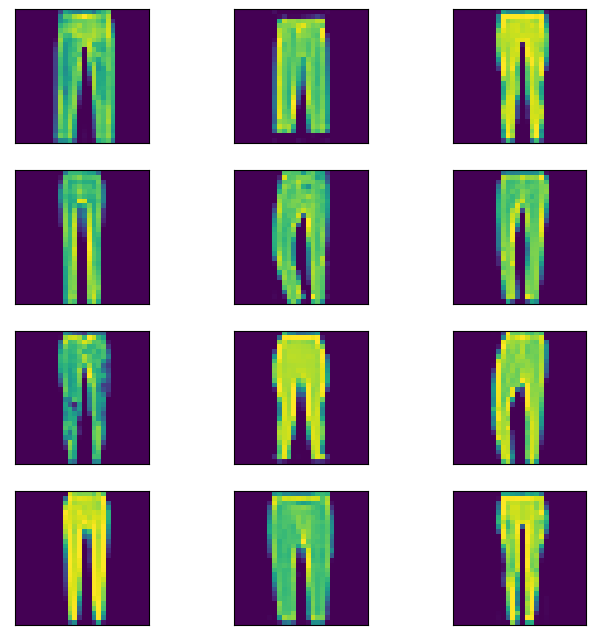

In [6]:
import matplotlib.pyplot as plt

# Display the first 12 images from dataset_firstname
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(dataset_ankit[i])
    ax.set_xticks([])
    ax.set_yticks([])
    if i == 11:
        break
plt.show()

In [7]:
import tensorflow as tf

# Creating TensorFlow dataset from dataset_firstname
train_dataset_ankit = tf.data.Dataset.from_tensor_slices(dataset_ankit)

# Shuffle the dataset and set batch size
train_dataset_ankit = train_dataset_ankit.shuffle(buffer_size=7000).batch(batch_size=256)

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, BatchNormalization, LeakyReLU, Conv2DTranspose

In [9]:
# Define the generator model
generator_model_ankit = Sequential()

# Add fully connected layer with 7*7*256 neurons
generator_model_ankit.add(Dense(units=7*7*256, input_shape=(100,), use_bias=False))

# Add batch normalization and LeakyReLU activation
generator_model_ankit.add(BatchNormalization())
generator_model_ankit.add(LeakyReLU(alpha=0.2))

# Add transposed convolutional layer with 128 kernels and a window size of 5x5
generator_model_ankit.add(Reshape((7, 7, 256)))
generator_model_ankit.add(Conv2DTranspose(filters=128, kernel_size=5, strides=1, padding='same', use_bias=False))
generator_model_ankit.add(BatchNormalization())
generator_model_ankit.add(LeakyReLU(alpha=0.2))

# Add transposed convolutional layer with 64 kernels and a window size of 5x5
generator_model_ankit.add(Conv2DTranspose(filters=64, kernel_size=5, strides=2, padding='same', use_bias=False))
generator_model_ankit.add(BatchNormalization())
generator_model_ankit.add(LeakyReLU(alpha=0.2))
# Add transposed convolutional layer with 1 kernel and a window size of 5x5
generator_model_ankit.add(Conv2DTranspose(filters=1, kernel_size=5, strides=2, padding='same', activation='tanh', use_bias=False))

# Print summary of the model
generator_model_ankit.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 12544)             1254400   
                                                                 
 batch_normalization (BatchN  (None, 12544)            50176     
 ormalization)                                                   
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 12544)             0         
                                                                 
 reshape (Reshape)           (None, 7, 7, 256)         0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 7, 7, 128)        819200    
 nspose)                                                         
                                                                 
 batch_normalization_1 (Batc  (None, 7, 7, 128)        5

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


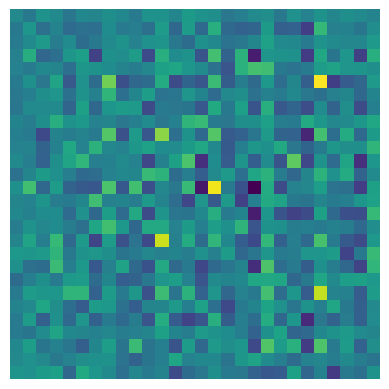

In [10]:
from tensorflow.keras.utils import plot_model
plot_model(generator_model_ankit, to_file='generator_model_ankit.png', show_shapes=True)

# create sample vector
sample_vector = tf.random.normal([1, 100])

# generate image from untrained generator
generated_image = generator_model_ankit(sample_vector, training=False)

# plot generated image
plt.imshow(generated_image[0, :, :, 0])
plt.axis('off')
plt.show()

In [11]:
from tensorflow.keras.layers import Conv2D, LeakyReLU, Dropout, Flatten, Dense, Reshape, Conv2DTranspose, BatchNormalization

# Define the generator model
discriminator_model_ankit = Sequential()

# Add the layers
discriminator_model_ankit.add(Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=(28, 28, 1)))
discriminator_model_ankit.add(LeakyReLU(alpha=0.2))
discriminator_model_ankit.add(Dropout(0.3))
discriminator_model_ankit.add(Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
discriminator_model_ankit.add(LeakyReLU(alpha=0.2))
discriminator_model_ankit.add(Dropout(0.3))
discriminator_model_ankit.add(Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
discriminator_model_ankit.add(BatchNormalization())
discriminator_model_ankit.add(LeakyReLU(alpha=0.2))
discriminator_model_ankit.add(Flatten())
discriminator_model_ankit.add(Dense(1, activation='sigmoid'))

In [12]:
# Print the summary of the model
discriminator_model_ankit.summary()

plot_model(discriminator_model_ankit, to_file='discriminator_model_Ankit.png', show_shapes=True)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 14, 14, 64)        1664      
                                                                 
 leaky_re_lu_3 (LeakyReLU)   (None, 14, 14, 64)        0         
                                                                 
 dropout (Dropout)           (None, 14, 14, 64)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 7, 7, 128)         204928    
                                                                 
 leaky_re_lu_4 (LeakyReLU)   (None, 7, 7, 128)         0         
                                                                 
 dropout_1 (Dropout)         (None, 7, 7, 128)         0         
                                                                 
 conv2d_transpose_3 (Conv2DT  (None, 14, 14, 64)      

In [13]:
# Define loss function
cross_entropy_ankit = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [14]:
# Define the optimizers for the generator and discriminator models
generator_optimizer_ankit = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer_ankit = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

In [15]:
@tf.function
def train_step(images):
    noise = tf.random.normal([256, 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
      generated_images = generator_model_ankit(noise, training=True)

      real_output = discriminator_model_ankit(images, training=True)
      fake_output = discriminator_model_ankit(generated_images, training=True)

      gen_loss = cross_entropy_ankit(tf.ones_like(fake_output), fake_output)
      real_loss = cross_entropy_ankit(tf.ones_like(real_output), real_output)
      fake_loss = cross_entropy_ankit(tf.zeros_like(fake_output), fake_output)
      disc_loss = real_loss + fake_loss

    gradients_of_generator = gen_tape.gradient(gen_loss, generator_model_ankit.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator_model_ankit.trainable_variables)

    generator_optimizer_ankit.apply_gradients(zip(gradients_of_generator, generator_model_ankit.trainable_variables))
    discriminator_optimizer_ankit.apply_gradients(zip(gradients_of_discriminator, discriminator_model_ankit.trainable_variables))

    return gen_loss, disc_loss

# Train for multiple epochs
num_epochs = 10
batch_size = 256
import time
for epoch in range(num_epochs):
    start_time = time.time()
    for batch_images in train_dataset_ankit:
        gen_loss, disc_loss = train_step(batch_images)
    epoch_time = time.time() - start_time
    
    print(f"Epoch {epoch+1} took {epoch_time:.2f} seconds. Generator loss: {gen_loss:.4f}. Discriminator loss: {disc_loss:.4f}")

C:\Users\ANKIT\AppData\Roaming\Python\Python39\site-packages\keras\backend.py:5673: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


Epoch 1 took 69.77 seconds. Generator loss: 0.7731. Discriminator loss: 0.9325
Epoch 2 took 68.82 seconds. Generator loss: 1.3298. Discriminator loss: 1.1049
Epoch 3 took 68.05 seconds. Generator loss: 2.3545. Discriminator loss: 0.8952
Epoch 4 took 69.49 seconds. Generator loss: 0.7747. Discriminator loss: 1.1139
Epoch 5 took 71.97 seconds. Generator loss: 0.9660. Discriminator loss: 1.3418
Epoch 6 took 69.02 seconds. Generator loss: 1.0175. Discriminator loss: 1.2789
Epoch 7 took 68.35 seconds. Generator loss: 1.1355. Discriminator loss: 1.2278
Epoch 8 took 69.63 seconds. Generator loss: 0.9452. Discriminator loss: 1.0257
Epoch 9 took 69.57 seconds. Generator loss: 0.7363. Discriminator loss: 1.3395
Epoch 10 took 69.02 seconds. Generator loss: 0.9554. Discriminator loss: 1.2467


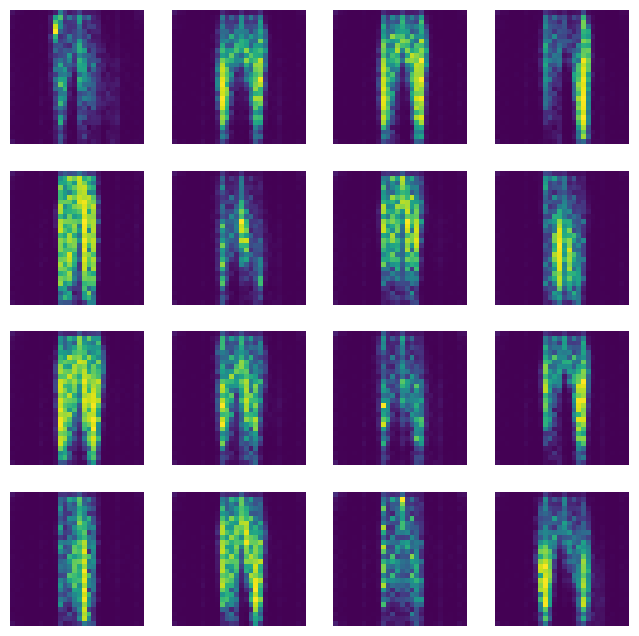

In [16]:
# Create 16 sample vectors
noise = tf.random.normal([16, 100])

# Generate images from the trained generator
generated_images = generator_model_ankit(noise, training=False)

# Normalize the pixel values
generated_images = (generated_images * 127.5) + 127.5

# Plot the generated images
fig = plt.figure(figsize=(8,8))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(generated_images[i, :, :, 0])
    plt.axis('off')

plt.show()